# Lab 9: Mạng nơ-ron nhiều lớp (MLP)

Ghi chú: tệp `xor.csv` không có kèm tài liệu nên được sinh mô phỏng theo đúng mô tả
(400 điểm trong hình vuông [-1, 1], lớp 1 ở góc trên phải và dưới trái, có ít nhiễu nhãn).
Vì vậy các con số ở mục 3 và bài tập 1 khác tài liệu một chút.

## 2. Tự tính lan truyền tiến (m1_lan_truyen_tien.py)

In [1]:
# -*- coding: utf-8 -*-
"""Bước 1: tự tính lan truyền tiến bằng numpy."""

import numpy as np


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def relu(z):
    return np.maximum(0, z)


# Phần 1: một nơ-ron với hàm sigmoid, chính là hồi quy logistic
w = np.array([0.8, -0.5, 0.3])
b = -0.2
x = np.array([2.0, 1.0, 3.0])
z = w @ x + b
print("Mot no-ron:")
print(f"  z = {w[0]}*{x[0]} + ({w[1]})*{x[1]} + {w[2]}*{x[2]}"
      f" + ({b}) = {z:.2f}")
print(f"  a = sigmoid(z) = {sigmoid(z):.4f}")
print()

# Phần 2: mạng 2 đầu vào, 2 nơ-ron ẩn ReLU, 1 nơ-ron ra
W1 = np.array([[1.0, 1.0],
               [1.0, 1.0]])
b1 = np.array([0.0, -1.0])
W2 = np.array([1.0, -2.0])
b2 = 0.0

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
print("Mang giai XOR:")
print("  x1  x2   h1  h2    y")
for x in X:
    h = relu(x @ W1 + b1)        # lớp ẩn
    y = h @ W2 + b2              # lớp ra
    print(f"  {x[0]:.0f}   {x[1]:.0f}    {h[0]:.0f}   {h[1]:.0f}"
          f"    {y:.0f}")
print()

# Cả bốn đầu vào cùng lúc bằng phép nhân ma trận
H = relu(X @ W1 + b1)
Y = H @ W2 + b2
print("Tinh ca bang mot lan:", Y)

Mot no-ron:
  z = 0.8*2.0 + (-0.5)*1.0 + 0.3*3.0 + (-0.2) = 1.80
  a = sigmoid(z) = 0.8581

Mang giai XOR:
  x1  x2   h1  h2    y
  0   0    0   0    0
  0   1    1   0    1
  1   0    1   0    1
  1   1    2   1    0

Tinh ca bang mot lan: [0. 1. 1. 0.]


## 3. Một nơ-ron và một lớp ẩn trên XOR (m2_xor.py)

In [2]:
"""Bước 2: một nơ-ron không giải được XOR, một lớp ẩn thì được."""

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

df = pd.read_csv("xor.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = LogisticRegression().fit(X_tr, y_tr)
print(f"Hoi quy logistic: {accuracy_score(y_te, lr.predict(X_te)):.4f}")
print()

# Dữ liệu nhỏ nên dùng solver="lbfgs", học nhanh và ổn định hơn
print("So no-ron an   so tham so   tap hoc   tap kiem tra")
for so in [1, 2, 4, 8]:
    mlp = MLPClassifier(hidden_layer_sizes=(so,), solver="lbfgs",
                        max_iter=5000, random_state=0)
    mlp.fit(X_tr, y_tr)
    so_ts = sum(w.size for w in mlp.coefs_)
    so_ts += sum(b.size for b in mlp.intercepts_)
    a_hoc = accuracy_score(y_tr, mlp.predict(X_tr))
    a_kt = accuracy_score(y_te, mlp.predict(X_te))
    print(f"     {so:2d}           {so_ts:3d}       {a_hoc:.4f}"
          f"    {a_kt:.4f}")

Hoi quy logistic: 0.4600

So no-ron an   so tham so   tap hoc   tap kiem tra
      1             5       0.6533    0.5900
      2             9       0.6533    0.5900
      4            17       0.9367    0.9200
      8            33       0.9067    0.8200


## 4. Độ lớn mạng và điều chuẩn (m3_do_lon_mang.py)

In [3]:
"""Bước 3: mạng to thì học vẹt, điều chuẩn bằng alpha thì đỡ."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def mang(lop_an, alpha):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=lop_an, alpha=alpha,
                      solver="lbfgs", max_iter=20000, random_state=0),
    )


print("Ba mang               tap hoc   tap kiem tra")
for ten, lop_an, alpha in [("(2,), alpha 1e-4", (2,), 1e-4),
                           ("(100, 100), 1e-5", (100, 100), 1e-5),
                           ("(100, 100), 1.0", (100, 100), 1.0)]:
    m = mang(lop_an, alpha).fit(X_tr, y_tr)
    print(f"  {ten:18s} {accuracy_score(y_tr, m.predict(X_tr)):.4f}"
          f"    {accuracy_score(y_te, m.predict(X_te)):.4f}")
print()

# Chọn alpha bằng kiểm định chéo, chỉ trên tập học
print("alpha      kiem dinh cheo")
diem = {}
for alpha in [1e-5, 1e-3, 0.1, 1.0, 3.0, 10.0]:
    diem[alpha] = cross_val_score(mang((100, 100), alpha),
                                  X_tr, y_tr, cv=5).mean()
    print(f"  {alpha:<8}  {diem[alpha]:.4f}")
a_tot = max(diem, key=diem.get)
m = mang((100, 100), a_tot).fit(X_tr, y_tr)
print(f"alpha tot nhat = {a_tot}, tap kiem tra "
      f"{accuracy_score(y_te, m.predict(X_te)):.4f}")

Ba mang               tap hoc   tap kiem tra
  (2,), alpha 1e-4   0.8444    0.8533


  (100, 100), 1e-5   1.0000    0.8267


  (100, 100), 1.0    0.8711    0.9067

alpha      kiem dinh cheo


  1e-05     0.7822


  0.001     0.7822


  0.1       0.7733


  1.0       0.8578


  3.0       0.8400


  10.0      0.8356


alpha tot nhat = 1.0, tap kiem tra 0.9067


## 5. Mạng nơ-ron khi quên chuẩn hoá (m4_chuan_hoa.py)

In [4]:
"""Bước 4: mạng nơ-ron khi quên chuẩn hoá."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("sinh_vien_mo_rong.csv")
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

tho = MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                    random_state=0).fit(X_tr, y_tr)
chuan = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000,
                  random_state=0),
).fit(X_tr, y_tr)

print(f"Doan bua ca lop qua : {y_te.mean():.4f}")
print(f"Khong chuan hoa     : "
      f"{accuracy_score(y_te, tho.predict(X_te)):.4f}")
print(f"Co chuan hoa        : "
      f"{accuracy_score(y_te, chuan.predict(X_te)):.4f}")
print()

# Mạng không chuẩn hoá đoán ra sao
du = tho.predict(X_te)
print("Khong chuan hoa, so ban doan qua:", du.sum(), "tren", len(du))

Doan bua ca lop qua : 0.6000
Khong chuan hoa     : 0.4000
Co chuan hoa        : 0.9000

Khong chuan hoa, so ban doan qua: 0 tren 30


## 6. Nhận dạng chữ số viết tay (m5_chu_so.py)

In [5]:
"""Bước 5: nhận dạng chữ số viết tay bằng MLP."""

import numpy as np
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

mang = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                  random_state=0),
).fit(X_tr, y_tr)
mlp = mang[-1]

print("Kich thuoc cac ma tran trong so:",
      [w.shape for w in mlp.coefs_])
so_ts = sum(w.size for w in mlp.coefs_)
so_ts += sum(b.size for b in mlp.intercepts_)
print("Tong so tham so:", so_ts)
print("So vong hoc:", mlp.n_iter_)
mm = mlp.loss_curve_
print(f"Mat mat vong 1: {mm[0]:.4f}, vong 10: {mm[9]:.4f},"
      f" vong cuoi: {mm[-1]:.4f}")
print()

du = mang.predict(X_te)
print(f"Accuracy tren tap kiem tra: {accuracy_score(y_te, du):.4f}")
sai = np.flatnonzero(du != y_te)
print("So anh doan sai:", len(sai), "tren", len(y_te))
for i in sai:
    print(f"  anh {i:3d}: that la {y_te[i]}, doan la {du[i]}")
print()

# Dừng sớm: giữ riêng 10% tập học để theo dõi
dung_som = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                  early_stopping=True, random_state=0),
).fit(X_tr, y_tr)
print("Dung som sau", dung_som[-1].n_iter_, "vong, accuracy",
      f"{accuracy_score(y_te, dung_som.predict(X_te)):.4f}")
print()

# So với các mô hình đã học, cùng tập học và tập kiểm tra
khac = {
    "Logistic co chuan hoa": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN, k = 5": KNeighborsClassifier(),
    "SVM kernel RBF": SVC(),
}
for ten, mh in khac.items():
    acc = accuracy_score(y_te, mh.fit(X_tr, y_tr).predict(X_te))
    print(f"{ten:22s} {acc:.4f}")

Kich thuoc cac ma tran trong so: [(64, 100), (100, 10)]
Tong so tham so: 7510
So vong hoc: 144
Mat mat vong 1: 2.5206, vong 10: 0.4448, vong cuoi: 0.0052

Accuracy tren tap kiem tra: 0.9844
So anh doan sai: 7 tren 450
  anh   6: that la 9, doan la 3
  anh  61: that la 5, doan la 7
  anh  77: that la 2, doan la 1
  anh  85: that la 9, doan la 7
  anh 276: that la 8, doan la 2
  anh 428: that la 7, doan la 9
  anh 443: that la 4, doan la 7



Dung som sau 44 vong, accuracy 0.9578

Logistic co chuan hoa  0.9711


KNN, k = 5             0.9867
SVM kernel RBF         0.9911


## 7. Bài tập
### Bài tập 1: Tự dự đoán bằng trọng số đã học

In [6]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

df = pd.read_csv("xor.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
mlp = MLPClassifier(hidden_layer_sizes=(8,), solver="lbfgs",
                    max_iter=5000, random_state=0).fit(X_tr, y_tr)

W1, W2 = mlp.coefs_
b1, b2 = mlp.intercepts_
print("Kich thuoc:", W1.shape, b1.shape, W2.shape, b2.shape)

X5 = X_te.to_numpy()[:5]
H = np.maximum(0, X5 @ W1 + b1)              # lớp ẩn ReLU
xs_tu_tinh = 1 / (1 + np.exp(-(H @ W2 + b2)))  # lớp ra sigmoid
xs_tu_tinh = xs_tu_tinh.ravel()
xs_thu_vien = mlp.predict_proba(X_te[:5])[:, 1]
print("   x1       x2      tu tinh        predict_proba")
for (a, b), p, q in zip(X5, xs_tu_tinh, xs_thu_vien):
    print(f"  {a:+.4f}  {b:+.4f}   {p:.10f}   {q:.10f}")
print("Chenh lech lon nhat:", np.abs(xs_tu_tinh - xs_thu_vien).max())
assert np.allclose(xs_tu_tinh, xs_thu_vien)

Kich thuoc: (2, 8) (8,) (8, 1) (1,)
   x1       x2      tu tinh        predict_proba
  +0.3447  -0.7430   0.0181875835   0.0181875835
  +0.5380  +0.5637   0.9928505738   0.9928505738
  +0.6425  -0.0032   0.7779471263   0.7779471263
  +0.7934  -0.3379   0.1504185054   0.1504185054
  -0.5081  -0.8092   0.9924594268   0.9924594268
Chenh lech lon nhat: 0.0


### Bài tập 2: Một mạng XOR khác

In [7]:
import numpy as np

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
W1 = np.array([[1.0, -1.0],     # h1 = max(0, x1 - x2)
               [-1.0, 1.0]])    # h2 = max(0, x2 - x1)
b1 = np.array([0.0, 0.0])
W2 = np.array([1.0, 1.0])       # y = h1 + h2

H = np.maximum(0, X @ W1 + b1)
Y = H @ W2
print("  x1  x2   h1  h2   y   XOR")
for x, h, yy in zip(X, H, Y):
    print(f"  {x[0]:.0f}   {x[1]:.0f}    {h[0]:.0f}   {h[1]:.0f}   {yy:.0f}"
          f"    {int(x[0]) ^ int(x[1])}")
assert np.array_equal(Y, np.logical_xor(X[:, 0], X[:, 1]).astype(float))

  x1  x2   h1  h2   y   XOR
  0   0    0   0   0    0
  0   1    0   1   1    1
  1   0    1   0   1    1
  1   1    0   0   0    0


### Bài tập 3: So các hàm kích hoạt

In [8]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print("activation   tap hoc   tap kiem tra")
for ham in ["logistic", "tanh", "relu"]:
    m = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(100, 100), alpha=1.0,
                      activation=ham, solver="lbfgs", max_iter=20000,
                      random_state=0),
    ).fit(X_tr, y_tr)
    print(f"  {ham:9s}  {accuracy_score(y_tr, m.predict(X_tr)):.4f}"
          f"    {accuracy_score(y_te, m.predict(X_te)):.4f}")

activation   tap hoc   tap kiem tra


  logistic   0.8400    0.8533


  tanh       0.8711    0.9067


  relu       0.8711    0.9067


### Bài tập 4: Tốc độ học

learning_rate_init   so vong   mat mat cuoi   tap kiem tra


      0.0001              582      0.0189        0.9889


      0.001               144      0.0052        0.9844


      0.01                 38      0.0011        0.9778


      0.1                  30      0.1347        0.9533


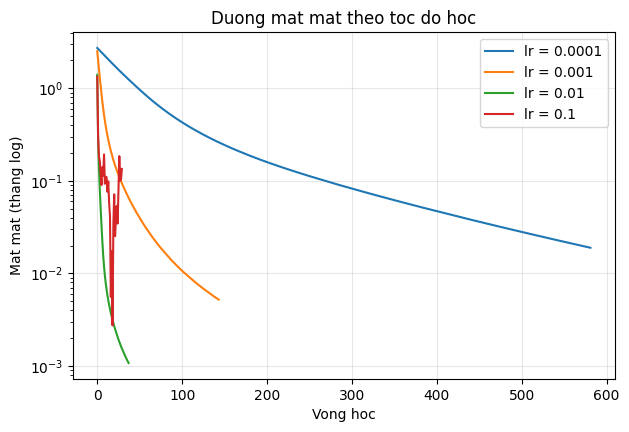

In [9]:
import warnings

import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
plt.figure(figsize=(7, 4.5))
print("learning_rate_init   so vong   mat mat cuoi   tap kiem tra")
for lr in [0.0001, 0.001, 0.01, 0.1]:
    with warnings.catch_warnings():
        # lr = 0.0001 học quá chậm, chạm max_iter là chuyện được dự kiến
        warnings.simplefilter("ignore", ConvergenceWarning)
        m = make_pipeline(
            StandardScaler(),
            MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000,
                          learning_rate_init=lr, random_state=0),
        ).fit(X_tr, y_tr)
    mlp = m[-1]
    print(f"      {lr:<8}          {mlp.n_iter_:5d}      {mlp.loss_curve_[-1]:.4f}"
          f"        {accuracy_score(y_te, m.predict(X_te)):.4f}")
    plt.plot(mlp.loss_curve_, label=f"lr = {lr}")
plt.yscale("log")
plt.xlabel("Vong hoc")
plt.ylabel("Mat mat (thang log)")
plt.title("Duong mat mat theo toc do hoc")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("toc_do_hoc.png", dpi=120, bbox_inches="tight")
plt.show()

### Bài tập 5: Dò lưới cho mạng nơ-ron

In [10]:
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
mh = make_pipeline(StandardScaler(),
                   MLPClassifier(max_iter=1000, random_state=0))
luoi = {"mlpclassifier__hidden_layer_sizes": [(10,), (50,), (100,), (50, 50)],
        "mlpclassifier__alpha": [0.0001, 0.01, 1]}
tim = GridSearchCV(mh, luoi, cv=5, n_jobs=-1).fit(X_tr, y_tr)

bang = pd.DataFrame(tim.cv_results_["params"])
bang.columns = ["alpha", "lop_an"]
bang["diem"] = tim.cv_results_["mean_test_score"]
bang["lop_an"] = bang["lop_an"].astype(str)
print(bang.pivot(index="lop_an", columns="alpha", values="diem").round(4).to_string())
print()
print("Cap tot nhat:", tim.best_params_)
print(f"Diem kiem dinh cheo: {tim.best_score_:.4f}")
print(f"Accuracy tap kiem tra: {tim.score(X_te, y_te):.4f} (SVM kernel RBF: 0.9911)")

alpha     0.0001  0.0100  1.0000
lop_an                          
(10,)     0.9480  0.9488  0.9651
(100,)    0.9755  0.9755  0.9777
(50, 50)  0.9681  0.9681  0.9777
(50,)     0.9740  0.9755  0.9785

Cap tot nhat: {'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (50,)}
Diem kiem dinh cheo: 0.9785
Accuracy tap kiem tra: 0.9822 (SVM kernel RBF: 0.9911)


### Bài tập 6: Mạng nơ-ron cho hồi quy

In [11]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17)

mo_hinh = {
    "Hoi quy tuyen tinh": LinearRegression(),
    "MLPRegressor (20,)": make_pipeline(
        StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(20,), max_iter=5000, random_state=0)),
}
can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print(f"Du lieu hoc co dien tich tu {X_tr['dien_tich'].min()} toi {X_tr['dien_tich'].max()} m2")
print("                     MAE      60m2    100m2   150m2   250m2")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    mae = mean_absolute_error(y_te, mh.predict(X_te))
    gia = mh.predict(can_moi)
    print(f"  {ten:18s} {mae:.4f}   " + "   ".join(f"{g:5.2f}" for g in gia))

Du lieu hoc co dien tich tu 37.6 toi 115.9 m2
                     MAE      60m2    100m2   150m2   250m2
  Hoi quy tuyen tinh 0.3123    5.14    8.28   12.21   20.07
  MLPRegressor (20,) 0.5050    5.01    8.35   14.93   28.63


## Summary

Dữ liệu `xor.csv` là bản mô phỏng tự sinh (400 điểm, có ít nhiễu nhãn), nên các con số ở mục 3 và bài tập 1 khác tài liệu. Các mục còn lại khớp tài liệu.

**Phần thực hành**
- Một nơ-ron: z = 1.80, sigmoid(z) = 0.8581. Mạng 2 nơ-ron ẩn ReLU tính đúng XOR: 0, 1, 1, 0.
- XOR: hồi quy logistic 0.4600, kém cả tung đồng xu. MLP 1 hoặc 2 nơ-ron ẩn 0.5900, 4 nơ-ron 0.9200, 8 nơ-ron 0.8200 (33 tham số). Cần ít nhất 4 nơ-ron ẩn để cắt được bốn góc.
- Hai vầng trăng: mạng (2,) 0.8444 / 0.8533 (cẩu thả). Mạng (100, 100) với alpha 1e-5: tập học 1.0000, tập kiểm tra 0.8267 (học vẹt). Cùng mạng với alpha = 1.0: 0.8711 / 0.9067. Kiểm định chéo chọn alpha = 1.0 (0.8578), tập kiểm tra 0.9067.
- Không chuẩn hoá: 0.4000, đoán mọi bạn đều rớt (0/30 qua). Có chuẩn hoá: 0.9000.
- Chữ số: 7510 tham số, 144 vòng, mất mát 2.5206 → 0.0052, accuracy 0.9844 (sai 7/450). Dừng sớm: 44 vòng, 0.9578. Logistic 0.9711, KNN 0.9867, SVM 0.9911.

**Bài tập**
1. Tự tính lan truyền tiến (ReLU ở lớp ẩn, sigmoid ở lớp ra) từ `coefs_` và `intercepts_` cho 5 điểm đầu của tập kiểm tra khớp `predict_proba` tới mọi chữ số thập phân (chênh lệch 0.0). Mạng MLP bên trong chỉ là hai phép nhân ma trận, một hàm ReLU và một hàm sigmoid.
2. Mạng h1 = max(0, x1 - x2), h2 = max(0, x2 - x1), y = h1 + h2 cho đúng 0, 1, 1, 0. h1 chỉ bật khi x1 > x2, h2 chỉ bật khi x2 > x1, nên y = |x1 - x2|. Với đầu vào 0 hoặc 1, y = 1 khi hai đầu vào khác nhau và y = 0 khi giống nhau, chính là XOR.
3. logistic: 0.8400 / 0.8533. tanh: 0.8711 / 0.9067. relu: 0.8711 / 0.9067. **tanh và relu ngang nhau và tốt nhất.** Sigmoid bão hoà nhanh, độ dốc nhỏ, cộng với alpha = 1 nên ranh giới gần như thẳng.
4. lr = 0.0001: 582 vòng, mất mát 0.0189, 0.9889. lr = 0.001: 144 vòng, 0.0052, 0.9844. lr = 0.01: 38 vòng, 0.0011, 0.9778. lr = 0.1: 30 vòng, 0.1347, 0.9533. Tốc độ học quá nhỏ thì học rất chậm, cần rất nhiều vòng. Tốc độ học quá lớn thì mỗi bước nhảy quá xa, mất mát dao động và dừng ở mức cao, accuracy giảm rõ. Hình lưu ở `toc_do_hoc.png`.
5. Tốt nhất: hidden_layer_sizes = (50,), alpha = 1, kiểm định chéo 0.9785. Tập kiểm tra 0.9822, **không vượt được** SVM kernel RBF (0.9911).
6. MAE trên tập kiểm tra: hồi quy tuyến tính 0.3123, MLPRegressor 0.5050, đường thẳng tốt hơn. Căn 250 m²: hồi quy tuyến tính đoán 20.07 tỷ, MLP đoán 28.63 tỷ. Dữ liệu học chỉ có diện tích từ 37.6 tới 115.9 m², ngoài vùng đó mạng nơ-ron kéo dài đoạn ReLU cuối cùng theo một độ dốc tuỳ ý (ở 150 m² đã lệch: 14.93 so với 12.21). Mạng nơ-ron **không ngoại suy tốt** như đường thẳng.